# VulnPriorAI — Vulnerability Prioritizer
## Notebook: Explainable, context-aware vulnerability ranking

This prototype ranks vulnerabilities using transparent risk factors. It is a prioritization aid, **not** a probability of compromise or a replacement for professional vulnerability management.

Inputs: CVSS (0–10), EPSS probability (0–1, optional), CISA KEV flag, public exploit availability, internet exposure, and asset criticality.

Outputs: ranked findings, score breakdown, priority category, explanation, and suggested urgency. We start with synthetic data. The formula and thresholds are illustrative and require local calibration before operational use.

## 0. Install libraries

In [1]:
!pip -q install pandas numpy matplotlib

## 1. Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
pd.set_option("display.max_colwidth", 120)

## 2. Synthetic test dataset
This is fictional demo data—not real CVEs. EPSS is a probability between 0 and 1.

In [3]:
demo = pd.DataFrame([
 {"cve":"DEMO-001","cvss":9.8,"epss":0.08,"kev":False,"exploit_available":True,"internet_exposed":False,"asset_criticality":"medium","description":"Severe issue on a test application"},
 {"cve":"DEMO-002","cvss":8.1,"epss":0.94,"kev":True,"exploit_available":True,"internet_exposed":True,"asset_criticality":"critical","description":"Actively exploited issue on an internet-facing service"},
 {"cve":"DEMO-003","cvss":7.5,"epss":0.12,"kev":False,"exploit_available":False,"internet_exposed":False,"asset_criticality":"low","description":"Issue on a low-criticality workstation"},
 {"cve":"DEMO-004","cvss":6.5,"epss":0.72,"kev":False,"exploit_available":True,"internet_exposed":True,"asset_criticality":"high","description":"Issue with public exploit and external exposure"},
 {"cve":"DEMO-005","cvss":5.3,"epss":0.01,"kev":False,"exploit_available":False,"internet_exposed":False,"asset_criticality":"medium","description":"Low-impact internal issue"},
 {"cve":"DEMO-006","cvss":10.0,"epss":0.55,"kev":True,"exploit_available":True,"internet_exposed":False,"asset_criticality":"critical","description":"Severe issue affecting a critical asset"}
])
display(demo)

,cve,cvss,epss,kev,exploit_available,internet_exposed,asset_criticality,description
0,DEMO-001,9.8,0.08,False,True,False,medium,Severe issue on a test application
1,DEMO-002,8.1,0.94,True,True,True,critical,Actively exploited issue on an internet-facing service
2,DEMO-003,7.5,0.12,False,False,False,low,Issue on a low-criticality workstation
3,DEMO-004,6.5,0.72,False,True,True,high,Issue with public exploit and external exposure
4,DEMO-005,5.3,0.01,False,False,False,medium,Low-impact internal issue
5,DEMO-006,10.0,0.55,True,True,False,critical,Severe issue affecting a critical asset


## 3. Optional CSV upload
Skip to use the demo data. CSV columns should match the example. Scanner exports may need mapping first.

In [4]:
# Uncomment to upload a CSV file:
# uploaded = files.upload()
# csv_name = next(iter(uploaded))
# df = pd.read_csv(csv_name)
# display(df.head())

df = demo.copy()

## 4. Normalize and validate inputs
Missing EPSS stays unknown (NaN), rather than being interpreted as zero risk.

In [5]:
def to_bool(v):
    if isinstance(v, bool): return v
    if pd.isna(v): return False
    return str(v).strip().lower() in {"true", "1", "yes", "y", "confirmed"}

required = ["cve", "cvss", "kev", "exploit_available", "internet_exposed", "asset_criticality"]
missing = [c for c in required if c not in df.columns]
if missing: raise ValueError(f"Missing columns: {missing}")
df["cvss"] = pd.to_numeric(df["cvss"], errors="coerce")
if df["cvss"].isna().any() or not df["cvss"].between(0,10).all(): raise ValueError("CVSS must be numeric, 0–10")
if "epss" not in df.columns: df["epss"] = np.nan
df["epss"] = pd.to_numeric(df["epss"], errors="coerce")
if not df["epss"].dropna().between(0,1).all(): raise ValueError("EPSS must be 0–1")
for col in ["kev", "exploit_available", "internet_exposed"]: df[col] = df[col].apply(to_bool)
df["asset_criticality"] = df["asset_criticality"].fillna("medium").astype(str).str.lower()
allowed = {"low", "medium", "high", "critical"}
invalid = set(df["asset_criticality"]) - allowed
if invalid: raise ValueError(f"Invalid criticality: {invalid}")
display(df)

,cve,cvss,epss,kev,exploit_available,internet_exposed,asset_criticality,description
0,DEMO-001,9.8,0.08,False,True,False,medium,Severe issue on a test application
1,DEMO-002,8.1,0.94,True,True,True,critical,Actively exploited issue on an internet-facing service
2,DEMO-003,7.5,0.12,False,False,False,low,Issue on a low-criticality workstation
3,DEMO-004,6.5,0.72,False,True,True,high,Issue with public exploit and external exposure
4,DEMO-005,5.3,0.01,False,False,False,medium,Low-impact internal issue
5,DEMO-006,10.0,0.55,True,True,False,critical,Severe issue affecting a critical asset


## 5. Scoring model
Illustrative weighted score, capped at 100:
- CVSS: CVSS × 4 (up to 40)
- EPSS: EPSS × 20 (up to 20; missing = unknown and contributes no points)
- KEV listing: +25
- Public exploit: +10
- Internet exposure: +10
- Asset criticality: low 0, medium 3, high 7, critical 10

This is a custom baseline—not an official standard. Calibrate and validate it for your environment.

In [6]:
CRITICALITY_POINTS = {"low":0, "medium":3, "high":7, "critical":10}
def score_row(row):
    parts = {
      "cvss_points": row["cvss"] * 4,
      "epss_points": 0 if pd.isna(row["epss"]) else row["epss"] * 20,
      "kev_points": 25 if row["kev"] else 0,
      "exploit_points": 10 if row["exploit_available"] else 0,
      "exposure_points": 10 if row["internet_exposed"] else 0,
      "asset_points": CRITICALITY_POINTS[row["asset_criticality"]]
    }
    return pd.Series({**parts, "risk_score": round(min(100, sum(parts.values())), 2)})

scores = df.apply(score_row, axis=1)
df = pd.concat([df, scores], axis=1)
def priority(s):
    if s >= 80: return "Critical"
    if s >= 60: return "High"
    if s >= 40: return "Medium"
    return "Low"
df["priority"] = df["risk_score"].apply(priority)
df = df.sort_values(["risk_score", "cvss"], ascending=False).reset_index(drop=True)
display(df[["cve","cvss","epss","kev","exploit_available","internet_exposed","asset_criticality","risk_score","priority"]])

,cve,cvss,epss,kev,exploit_available,internet_exposed,asset_criticality,risk_score,priority
0,DEMO-002,8.1,0.94,True,True,True,critical,100.0,Critical
1,DEMO-006,10.0,0.55,True,True,False,critical,96.0,Critical
2,DEMO-004,6.5,0.72,False,True,True,high,67.4,High
3,DEMO-001,9.8,0.08,False,True,False,medium,53.8,Medium
4,DEMO-003,7.5,0.12,False,False,False,low,32.4,Low
5,DEMO-005,5.3,0.01,False,False,False,medium,24.4,Low


## 6. Explain the ranking

In [7]:
def explain(row):
    reasons=[]
    if row["kev"]: reasons.append("listed in KEV (known exploitation)")
    if row["exploit_available"]: reasons.append("public exploit availability reported")
    if row["internet_exposed"]: reasons.append("internet-facing asset")
    if row["asset_criticality"] == "critical": reasons.append("critical business asset")
    elif row["asset_criticality"] == "high": reasons.append("high-criticality asset")
    if pd.notna(row["epss"]) and row["epss"] >= .5: reasons.append(f"elevated EPSS ({row['epss']:.0%})")
    if not reasons: reasons.append("primarily driven by CVSS and available context")
    return "; ".join(reasons)
df["explanation"] = df.apply(explain, axis=1)
display(df[["cve","priority","risk_score","explanation"]])

,cve,priority,risk_score,explanation
0,DEMO-002,Critical,100.0,listed in KEV (known exploitation); public exploit availability reported; internet-facing asset; critical business a...
1,DEMO-006,Critical,96.0,listed in KEV (known exploitation); public exploit availability reported; critical business asset; elevated EPSS (55%)
2,DEMO-004,High,67.4,public exploit availability reported; internet-facing asset; high-criticality asset; elevated EPSS (72%)
3,DEMO-001,Medium,53.8,public exploit availability reported
4,DEMO-003,Low,32.4,primarily driven by CVSS and available context
5,DEMO-005,Low,24.4,primarily driven by CVSS and available context


## 7. Suggested urgency (illustrative policy only)

In [8]:
urgency = {
 "Critical":"Urgent triage; validate exposure and mitigation immediately",
 "High":"Prioritize remediation in the next expedited patch window",
 "Medium":"Plan remediation in the normal maintenance cycle",
 "Low":"Track and remediate according to policy"
}
df["recommended_action"] = df["priority"].map(urgency)
display(df[["cve","priority","risk_score","recommended_action"]])

,cve,priority,risk_score,recommended_action
0,DEMO-002,Critical,100.0,Urgent triage; validate exposure and mitigation immediately
1,DEMO-006,Critical,96.0,Urgent triage; validate exposure and mitigation immediately
2,DEMO-004,High,67.4,Prioritize remediation in the next expedited patch window
3,DEMO-001,Medium,53.8,Plan remediation in the normal maintenance cycle
4,DEMO-003,Low,32.4,Track and remediate according to policy
5,DEMO-005,Low,24.4,Track and remediate according to policy


## 8. Visualize priorities

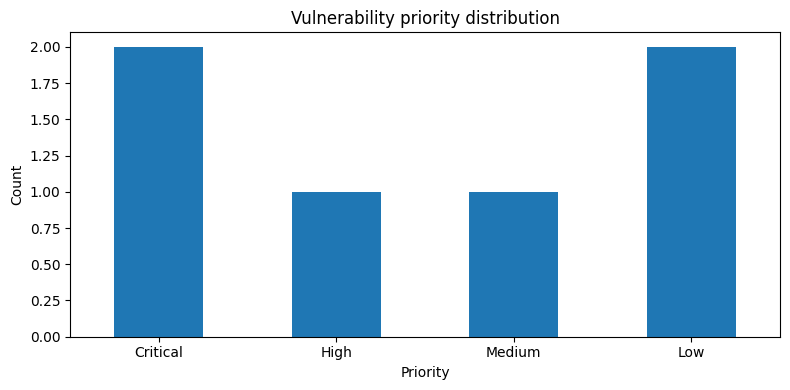

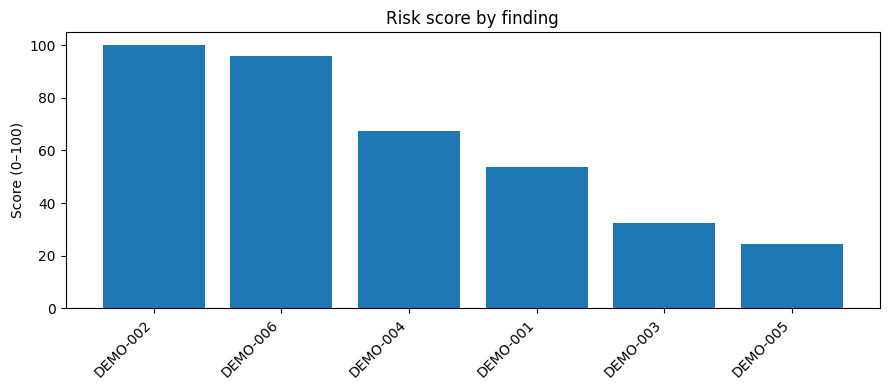

In [9]:
order=["Critical","High","Medium","Low"]
counts=df["priority"].value_counts().reindex(order,fill_value=0)
plt.figure(figsize=(8,4)); counts.plot(kind="bar"); plt.title("Vulnerability priority distribution"); plt.xlabel("Priority"); plt.ylabel("Count"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
plt.figure(figsize=(9,4)); plt.bar(df["cve"],df["risk_score"]); plt.title("Risk score by finding"); plt.ylabel("Score (0–100)"); plt.xticks(rotation=45,ha="right"); plt.tight_layout(); plt.show()

## 9. Export ranked results

In [10]:
cols=["cve","cvss","epss","kev","exploit_available","internet_exposed","asset_criticality","risk_score","priority","explanation","recommended_action"]
report=df[cols].copy()
report.to_csv("vulnpriorai_ranked_report.csv",index=False)
print("CSV saved: vulnpriorai_ranked_report.csv")
# Uncomment to download in Colab:
# files.download("vulnpriorai_ranked_report.csv")

CSV saved: vulnpriorai_ranked_report.csv
